In [2]:
import csv
import json
from pathlib import Path

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

LABEL_NAMES = {
    0: 'Normal',
    1: 'COVID',
    2: 'Viral Pneumonia',
    3: 'Lung_Opacity',
}
TRAIN_SEED = 42
VALIDATION_TEST_SEED = 41

# Tìm repo root từ thư mục kernel hiện tại, không phụ thuộc nơi gọi Jupyter.
PROJECT_ROOT = None
for candidate in (Path.cwd(), *Path.cwd().parents):
    if (candidate / 'src' / 'feature_extraction.ipynb').is_file() and (candidate / 'requirements.txt').is_file():
        PROJECT_ROOT = candidate
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        'Không tìm thấy project root. Hãy mở Jupyter từ thư mục project hoặc thư mục src.'
    )

FEATURES_PATH = PROJECT_ROOT / 'Data' / 'Features' / 'x_features.npy'
LABELS_PATH = PROJECT_ROOT / 'Data' / 'Features' / 'y_labels.npy'
OUTPUT_DIR = PROJECT_ROOT / 'Model'
print(f'Project: {PROJECT_ROOT}')
print(f'Features: {FEATURES_PATH}')
print(f'Labels: {LABELS_PATH}')

Project: d:\user\study_school\MachineLearning\project\BigProject_MachineLearning
Features: d:\user\study_school\MachineLearning\project\BigProject_MachineLearning\Data\Features\x_features.npy
Labels: d:\user\study_school\MachineLearning\project\BigProject_MachineLearning\Data\Features\y_labels.npy


In [3]:
missing_files = [path for path in (FEATURES_PATH, LABELS_PATH) if not path.is_file()]
if missing_files:
    missing_list = '\n'.join(f'- {path}' for path in missing_files)
    raise FileNotFoundError(
        'Thiếu dữ liệu đặc trưng. Hãy chạy src/feature_extraction.ipynb trước.\n'
        f'{missing_list}'
    )

X = np.load(FEATURES_PATH)
y = np.load(LABELS_PATH)
if X.ndim != 2 or y.ndim != 1 or len(X) != len(y):
    raise ValueError(f'Kích thước dữ liệu không hợp lệ: X={X.shape}, y={y.shape}')
if not np.isfinite(X).all():
    raise ValueError('Ma trận đặc trưng có NaN hoặc giá trị vô hạn.')
if set(np.unique(y).tolist()) != set(LABEL_NAMES):
    raise ValueError(f'Không khớp mã lớp: nhận được {np.unique(y)}')

X = X.astype(np.float32, copy=False)
y = y.astype(np.int64, copy=False)
print(f'X shape/dtype: {X.shape} / {X.dtype}')
print(f'y shape/dtype: {y.shape} / {y.dtype}')
print('Số mẫu theo lớp:', {LABEL_NAMES[int(label)]: int(count) for label, count in zip(*np.unique(y, return_counts=True))})

X shape/dtype: (21165, 574) / float32
y shape/dtype: (21165,) / int64
Số mẫu theo lớp: {'Normal': 10192, 'COVID': 3616, 'Viral Pneumonia': 1345, 'Lung_Opacity': 6012}


In [4]:
X_train, X_val_test, y_train, y_val_test = train_test_split(
    X, y, test_size=0.2, random_state=TRAIN_SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_val_test, y_val_test, test_size=0.5,
    random_state=VALIDATION_TEST_SEED, stratify=y_val_test
)
print(f'Train: {len(y_train)} | Validation: {len(y_val)} | Test: {len(y_test)}')

Train: 16932 | Validation: 2116 | Test: 2117


In [5]:
CANDIDATES = [
    {'max_depth': 4, 'learning_rate': 0.08, 'n_estimators': 180},
    {'max_depth': 6, 'learning_rate': 0.08, 'n_estimators': 180},
]

def make_model(parameters):
    return XGBClassifier(
        objective='multi:softprob',
        num_class=len(LABEL_NAMES),
        eval_metric='mlogloss',
        tree_method='hist',
        n_jobs=-1,
        random_state=TRAIN_SEED,
        subsample=0.9,
        colsample_bytree=0.9,
        reg_lambda=1.0,
        **parameters,
    )

validation_results = []
best_parameters = None
best_validation_macro_f1 = -1.0
for parameters in CANDIDATES:
    candidate_model = make_model(parameters)
    candidate_model.fit(X_train, y_train, verbose=False)
    validation_predictions = candidate_model.predict(X_val)
    score = float(f1_score(y_val, validation_predictions, average='macro'))
    validation_results.append({'parameters': parameters, 'validation_macro_f1': score})
    print(f'Validation macro-F1 {parameters}: {score:.4f}')
    if score > best_validation_macro_f1:
        best_validation_macro_f1 = score
        best_parameters = parameters

print('Cấu hình được chọn:', best_parameters)

Validation macro-F1 {'max_depth': 4, 'learning_rate': 0.08, 'n_estimators': 180}: 0.8121
Validation macro-F1 {'max_depth': 6, 'learning_rate': 0.08, 'n_estimators': 180}: 0.8340
Cấu hình được chọn: {'max_depth': 6, 'learning_rate': 0.08, 'n_estimators': 180}


In [6]:
if best_parameters is None:
    raise RuntimeError('Không chọn được cấu hình XGBoost.')

X_train_validation = np.concatenate((X_train, X_val), axis=0)
y_train_validation = np.concatenate((y_train, y_val), axis=0)
final_model = make_model(best_parameters)
final_model.fit(X_train_validation, y_train_validation, verbose=False)
test_predictions = final_model.predict(X_test).astype(int)

class_ids = list(LABEL_NAMES)
class_names = [LABEL_NAMES[class_id] for class_id in class_ids]
report = classification_report(
    y_test, test_predictions, labels=class_ids, target_names=class_names,
    output_dict=True, zero_division=0
)
test_accuracy = float(accuracy_score(y_test, test_predictions))
test_macro_f1 = float(f1_score(y_test, test_predictions, average='macro'))
test_weighted_f1 = float(f1_score(y_test, test_predictions, average='weighted'))
print(f'Test accuracy: {test_accuracy:.4f}')
print(f'Test macro-F1: {test_macro_f1:.4f}')
print(f'Test weighted-F1: {test_weighted_f1:.4f}')
print('Báo cáo theo lớp:')
for class_name in class_names:
    row = report[class_name]
    print(f"{class_name}: precision={row['precision']:.4f}, recall={row['recall']:.4f}, f1={row['f1-score']:.4f}, support={int(row['support'])}")

Test accuracy: 0.8446
Test macro-F1: 0.8277
Test weighted-F1: 0.8413
Báo cáo theo lớp:
Normal: precision=0.8449, recall=0.9352, f1=0.8878, support=1019
COVID: precision=0.8269, recall=0.6464, f1=0.7256, support=362
Viral Pneumonia: precision=0.9397, recall=0.8134, f1=0.8720, support=134
Lung_Opacity: precision=0.8339, recall=0.8173, f1=0.8255, support=602


In [7]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

report_path = OUTPUT_DIR / 'xgboost_classification_report.csv'
report_columns = ('precision', 'recall', 'f1-score', 'support')
with report_path.open('w', newline='', encoding='utf-8') as csv_file:
    writer = csv.writer(csv_file)
    writer.writerow(('class', *report_columns))
    for name, values in report.items():
        if isinstance(values, dict):
            row = tuple(values.get(column, '') for column in report_columns)
        else:
            row = ('', '', values, len(y_test))
        writer.writerow((name, *row))

confusion = confusion_matrix(y_test, test_predictions, labels=class_ids)
confusion_path = OUTPUT_DIR / 'xgboost_confusion_matrix.csv'
with confusion_path.open('w', newline='', encoding='utf-8') as csv_file:
    writer = csv.writer(csv_file)
    writer.writerow(('actual/predicted', *class_names))
    for name, row in zip(class_names, confusion):
        writer.writerow((name, *row.tolist()))

metrics = {
    'test_accuracy': test_accuracy,
    'test_macro_f1': test_macro_f1,
    'test_weighted_f1': test_weighted_f1,
    'selected_parameters': best_parameters,
    'validation_candidates': validation_results,
    'class_mapping': LABEL_NAMES,
    'split_sample_counts': {'train': len(y_train), 'validation': len(y_val), 'test': len(y_test)},
    'split': {'method': 'stratified 80/10/10', 'train_random_state': TRAIN_SEED, 'validation_test_random_state': VALIDATION_TEST_SEED},
}
(OUTPUT_DIR / 'xgboost_metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
final_model.save_model(OUTPUT_DIR / 'xgboost_model.json')
print(f'Đã lưu model và báo cáo tại {OUTPUT_DIR}')

Đã lưu model và báo cáo tại d:\user\study_school\MachineLearning\project\BigProject_MachineLearning\Model


In [8]:
reloaded_model = XGBClassifier()
reloaded_model.load_model(OUTPUT_DIR / 'xgboost_model.json')
reloaded_predictions = reloaded_model.predict(X_test[:10]).astype(int)
assert np.array_equal(reloaded_predictions, test_predictions[:10])
print('Nạp model thành công; dự đoán sau khi nạp khớp với dự đoán trước khi lưu.')

Nạp model thành công; dự đoán sau khi nạp khớp với dự đoán trước khi lưu.


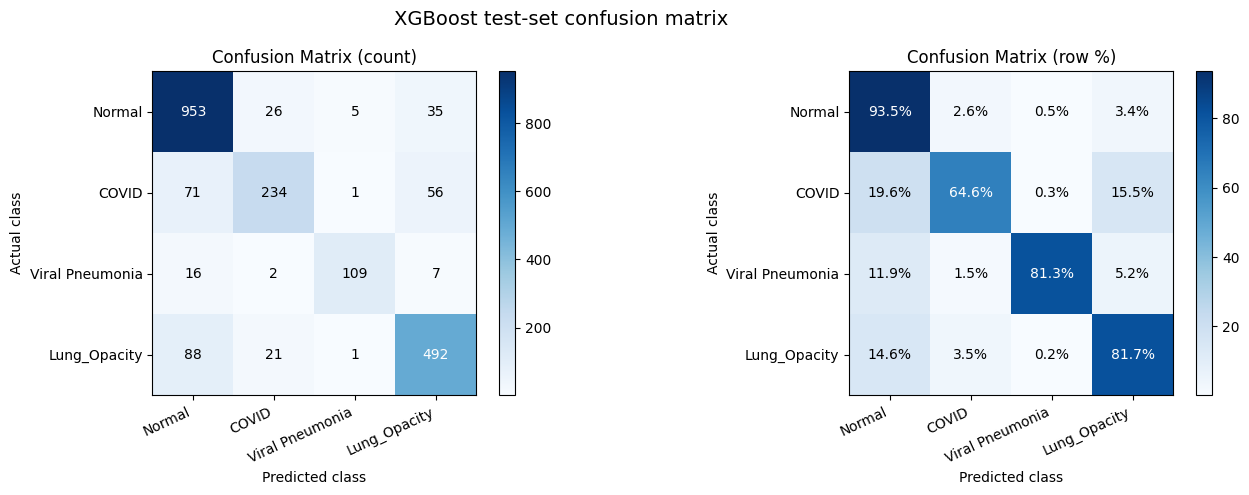

In [9]:

import matplotlib.pyplot as plt

row_totals = confusion.sum(axis=1, keepdims=True)
confusion_percent = np.divide(
    confusion.astype(float) * 100, row_totals,
    out=np.zeros_like(confusion, dtype=float), where=row_totals != 0
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, matrix, title, value_format in [
    (axes[0], confusion, 'Confusion Matrix (count)', 'd'),
    (axes[1], confusion_percent, 'Confusion Matrix (row %)', '.1f'),
]:
    image = ax.imshow(matrix, cmap='Blues')
    ax.set_title(title)
    ax.set_xlabel('Predicted class')
    ax.set_ylabel('Actual class')
    ax.set_xticks(range(len(class_names)), class_names, rotation=25, ha='right')
    ax.set_yticks(range(len(class_names)), class_names)
    threshold = float(np.max(matrix)) / 2 if np.max(matrix) else 0
    for row in range(matrix.shape[0]):
        for col in range(matrix.shape[1]):
            if value_format == 'd':
                value = format(int(matrix[row, col]), value_format)
            else:
                value = format(matrix[row, col], value_format) + '%'
            ax.text(
                col, row, value, ha='center', va='center',
                color='white' if matrix[row, col] > threshold else 'black'
            )
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
fig.suptitle('XGBoost test-set confusion matrix', fontsize=14)
fig.tight_layout()
plt.show()


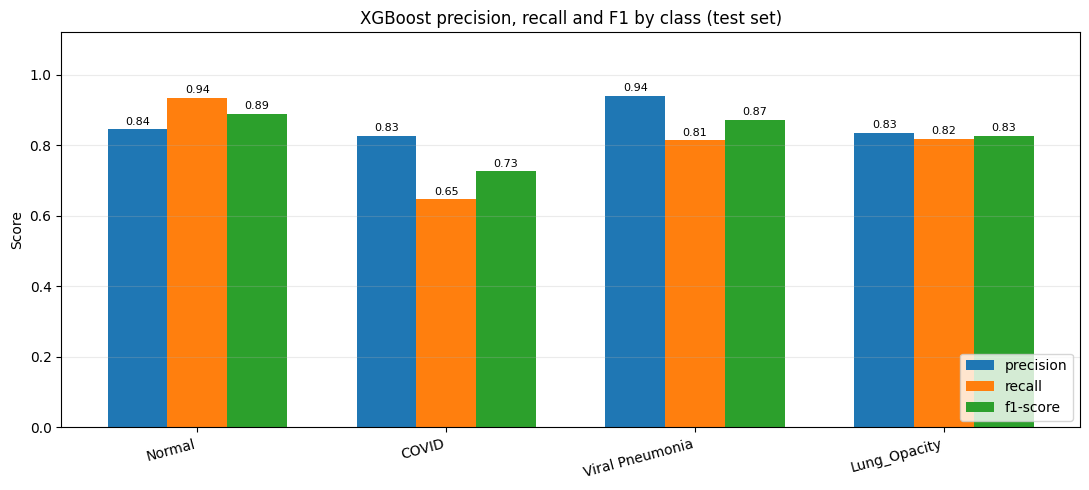

In [10]:

metric_names = ['precision', 'recall', 'f1-score']
class_metric_values = {
    metric: [report[name][metric] for name in class_names]
    for metric in metric_names
}

x_positions = np.arange(len(class_names))
bar_width = 0.24
fig, ax = plt.subplots(figsize=(11, 5))
for offset, metric in enumerate(metric_names):
    positions = x_positions + (offset - 1) * bar_width
    bars = ax.bar(positions, class_metric_values[metric], width=bar_width, label=metric)
    ax.bar_label(bars, fmt='%.2f', padding=2, fontsize=8)
ax.set_xticks(x_positions, class_names, rotation=15, ha='right')
ax.set_ylim(0, 1.12)
ax.set_ylabel('Score')
ax.set_title('XGBoost precision, recall and F1 by class (test set)')
ax.legend(loc='lower right')
ax.grid(axis='y', alpha=0.25)
fig.tight_layout()
plt.show()


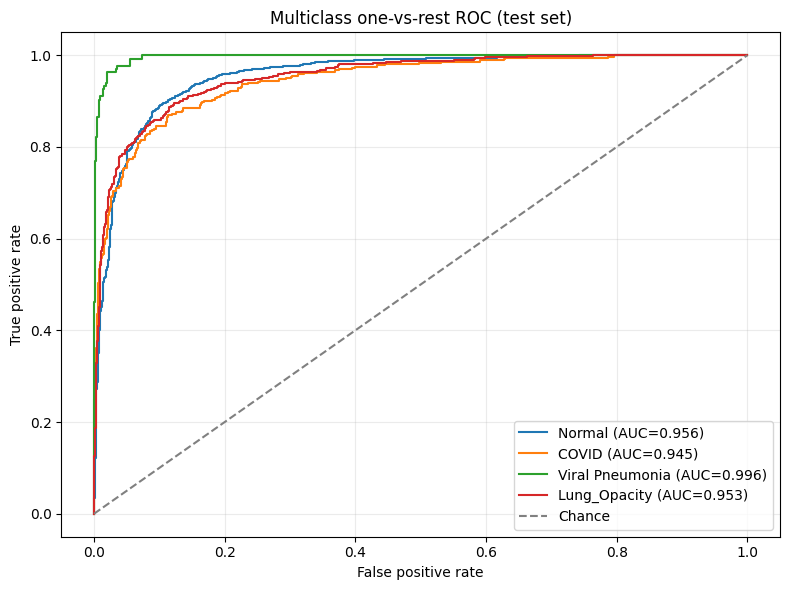

In [11]:

from sklearn.metrics import auc, roc_curve
from sklearn.preprocessing import label_binarize

y_test_binarized = label_binarize(y_test, classes=class_ids)
test_probabilities = final_model.predict_proba(X_test)
fig, ax = plt.subplots(figsize=(8, 6))
for class_index, class_name in enumerate(class_names):
    false_positive_rate, true_positive_rate, _ = roc_curve(
        y_test_binarized[:, class_index], test_probabilities[:, class_index]
    )
    class_auc = auc(false_positive_rate, true_positive_rate)
    ax.plot(
        false_positive_rate, true_positive_rate,
        label=f'{class_name} (AUC={class_auc:.3f})'
    )
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Chance')
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
ax.set_title('Multiclass one-vs-rest ROC (test set)')
ax.legend(loc='lower right')
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


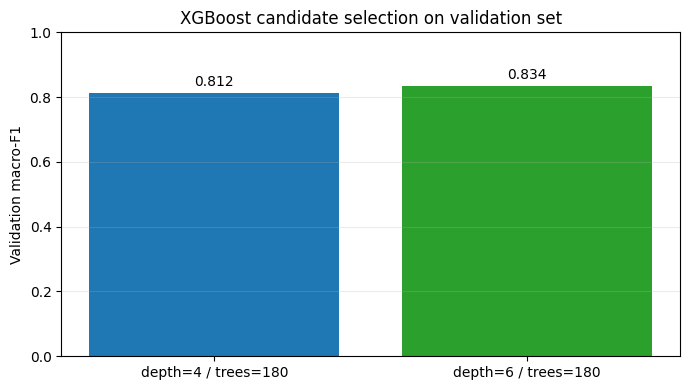

In [12]:

candidate_labels = [
    f"depth={item['parameters']['max_depth']} / trees={item['parameters']['n_estimators']}"
    for item in validation_results
]
candidate_scores = [item['validation_macro_f1'] for item in validation_results]
bar_colors = [
    'tab:green' if item['parameters'] == best_parameters else 'tab:blue'
    for item in validation_results
]
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(candidate_labels, candidate_scores, color=bar_colors)
ax.bar_label(bars, fmt='%.3f', padding=3)
ax.set_ylim(0, 1)
ax.set_ylabel('Validation macro-F1')
ax.set_title('XGBoost candidate selection on validation set')
ax.grid(axis='y', alpha=0.25)
fig.tight_layout()
plt.show()
